## 에어비엔비 가격?
- 평가: R-Squared, MAE, MSE, RMSE, MSLE, RMSLE, MAPE
- target : price(가격)

[제출 형식]

① CSV 파일명: `result.csv`

② 예측 가격 컬럼명: pred

③ 제출 컬럼 개수: pred 컬럼 1개

④ 평가용 데이터 개수와 예측 결과 데이터 개수 일치: 9,779개

- 제출 CSV 파일 예시
~~~
pred
238
183
234
~~~


### 평가(회귀)
~~~
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, root_mean_squared_error
from sklearn.metrics import mean_squared_log_error, root_mean_squared_log_error, mean_absolute_percentage_error

# R-Squared
print(r2_score(y_test, pred))

# MAE
print(mean_absolute_error(y_test, pred))

# MSE
print(mean_squared_error(y_test, pred))

# RMSE
print(root_mean_squared_error(y_test, pred))

# MSLE (음수 예측값이 있으면 ValueError → 0으로 올린 뒤 계산)
print(mean_squared_log_error(y_test, pred.clip(0)))

# RMSLE (음수 예측값이 있으면 ValueError → 0으로 올린 뒤 계산)
print(root_mean_squared_log_error(y_test, pred.clip(0)))

# MAPE (비율로 나옴, 0.25 = 25%)
print(mean_absolute_percentage_error(y_test, pred))
~~~


In [79]:
# 1. 문제 정의
# 회귀 문제
# y: price
# 제출 파일: result.csv

# 2. 데이터 불러오기
import pandas as pd
train = pd.read_csv("https://raw.githubusercontent.com/lovedlim/inf/refs/heads/main/p2/ex2/train.csv")
test = pd.read_csv("https://raw.githubusercontent.com/lovedlim/inf/refs/heads/main/p2/ex2/test.csv")


In [80]:
# 3. 탐색(EDA)
print(train.shape, test.shape)

train.head()

(39116, 11) (9779, 10)


,neighbourhood_group,neighbourhood,latitude,longitude,room_type,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,price
0,Brooklyn,Bushwick,40.69796,-73.92915,Entire home/apt,30,0,0.00,2,179,198
1,Manhattan,Washington Heights,40.83490,-73.94829,Entire home/apt,3,36,1.13,1,5,150
2,Brooklyn,Bushwick,40.69932,-73.91191,Entire home/apt,3,7,0.48,1,6,200
3,Brooklyn,Williamsburg,40.71520,-73.96230,Entire home/apt,31,2,0.06,1,0,230
4,Brooklyn,Bedford-Stuyvesant,40.69168,-73.95397,Entire home/apt,21,1,0.08,1,25,145


In [81]:
test.head()

,neighbourhood_group,neighbourhood,latitude,longitude,room_type,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,Manhattan,Theater District,40.75965,-73.98652,Entire home/apt,29,0,0.00,327,338
1,Brooklyn,Bedford-Stuyvesant,40.68062,-73.94418,Entire home/apt,30,1,0.75,6,284
2,Brooklyn,Williamsburg,40.70665,-73.94061,Entire home/apt,4,50,0.51,1,331
3,Brooklyn,Bedford-Stuyvesant,40.68427,-73.95460,Private room,1,18,3.33,1,16
4,Manhattan,Harlem,40.82028,-73.95381,Private room,1,3,0.08,1,0


In [82]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39116 entries, 0 to 39115
Data columns (total 11 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   neighbourhood_group             39116 non-null  object 
 1   neighbourhood                   39116 non-null  object 
 2   latitude                        39116 non-null  float64
 3   longitude                       39116 non-null  float64
 4   room_type                       39116 non-null  object 
 5   minimum_nights                  39116 non-null  int64  
 6   number_of_reviews               39116 non-null  int64  
 7   reviews_per_month               39116 non-null  float64
 8   calculated_host_listings_count  39116 non-null  int64  
 9   availability_365                39116 non-null  int64  
 10  price                           39116 non-null  int64  
dtypes: float64(3), int64(5), object(3)
memory usage: 3.3+ MB


In [83]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9779 entries, 0 to 9778
Data columns (total 10 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   neighbourhood_group             9779 non-null   object 
 1   neighbourhood                   9779 non-null   object 
 2   latitude                        9779 non-null   float64
 3   longitude                       9779 non-null   float64
 4   room_type                       9779 non-null   object 
 5   minimum_nights                  9779 non-null   int64  
 6   number_of_reviews               9779 non-null   int64  
 7   reviews_per_month               9779 non-null   float64
 8   calculated_host_listings_count  9779 non-null   int64  
 9   availability_365                9779 non-null   int64  
dtypes: float64(3), int64(4), object(3)
memory usage: 764.1+ KB


In [84]:
train.describe()

,latitude,longitude,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,price
count,39116.000000,39116.000000,39116.000000,39116.000000,39116.000000,39116.000000,39116.000000,39116.000000
mean,40.729054,-73.952084,7.022395,23.268509,1.090076,7.206182,112.718478,153.057547
std,0.054451,0.046106,19.547706,44.625410,1.598609,33.100783,131.479798,248.758522
min,40.499790,-74.244420,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,40.690250,-73.983060,1.000000,1.000000,0.040000,1.000000,0.000000,69.000000
50%,40.723060,-73.955680,3.000000,5.000000,0.370000,1.000000,45.000000,105.000000
75%,40.763130,-73.936017,5.000000,23.000000,1.572500,2.000000,225.000000,175.000000
max,40.913060,-73.712990,999.000000,607.000000,58.500000,327.000000,365.000000,10000.000000


<Axes: >

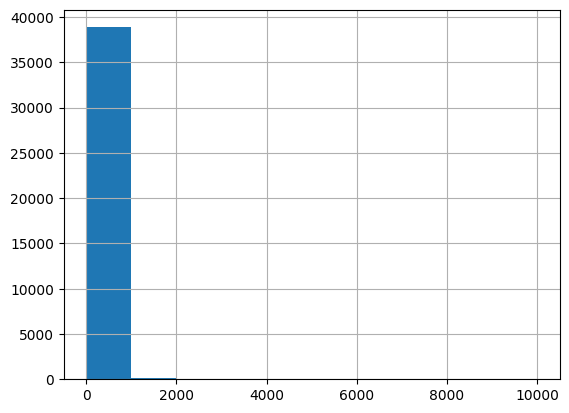

In [85]:
# 영상 참고 및 추후 추가
# 시험에서는 시각화 안 됨.
train['price'].hist()

In [86]:
# 4. 전처리
# X/y split

y_train = train.pop('price')
X_train = train

In [87]:
# one-hot encoding
X_train = pd.get_dummies(X_train, dtype=int)
test = pd.get_dummies(test, dtype=int)

# 특수 문자 방지
X_train.columns = X_train.columns.str.replace(r'[\[\]\{\}":,]', '_', regex=True)
test.columns = test.columns.str.replace(r'[\[\]\{\}":,]', '_', regex=True)

# 컬럼명 train 데이터에 맞추기
# 이전 코드 참고
X_train, test = X_train.align(test, join='left', axis=1, fill_value=0)

In [88]:
# 5. 검증 데이터 분리
from sklearn.model_selection import train_test_split

X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)
print(X_tr.shape, y_tr.shape, X_val.shape, y_val.shape)

(31292, 236) (31292,) (7824, 236) (7824,)


In [89]:
# 6. 학습 및 평가
# 6-1. Random Forest
# 라이브러리는 검색함.
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(random_state=42)
rf.fit(X_tr, y_tr)
y_pred_rf = rf.predict(X_val)

# 평가
# 위에 주어진 코드 복사 및 수정
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, root_mean_squared_error
from sklearn.metrics import mean_squared_log_error, root_mean_squared_log_error, mean_absolute_percentage_error

# R-Squared
print(r2_score(y_val, y_pred_rf))

# MAE
print(mean_absolute_error(y_val, y_pred_rf))

# MSE
print(mean_squared_error(y_val, y_pred_rf))

# RMSE
print(root_mean_squared_error(y_val, y_pred_rf))

# MSLE (음수 예측값이 있으면 ValueError → 0으로 올린 뒤 계산)
print(mean_squared_log_error(y_val, y_pred_rf.clip(0)))

# RMSLE (음수 예측값이 있으면 ValueError → 0으로 올린 뒤 계산)
print(root_mean_squared_log_error(y_val, y_pred_rf.clip(0)))

# MAPE (비율로 나옴, 0.25 = 25%)
print(mean_absolute_percentage_error(y_val, y_pred_rf))

0.09636891046949214
67.58117586912066
46568.19455398205
215.79665093319232
0.24731858318810016
0.49731135437279145
0.46527128559372605


In [90]:
# 6-2. LightGBM
# 라이브러리는 검색함
from lightgbm import LGBMRegressor

# verbose=-1는 답지 참고. 왜 추가하는지 모르겠음.
lgbm = LGBMRegressor(random_state=42, verbose=-1)
lgbm.fit(X_tr, y_tr)
y_pred_lgbm = lgbm.predict(X_val)

# 평가
# 위에 주어진 코드 복사 및 수정
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, root_mean_squared_error
from sklearn.metrics import mean_squared_log_error, root_mean_squared_log_error, mean_absolute_percentage_error

# R-Squared
print(r2_score(y_val, y_pred_lgbm))

# MAE
print(mean_absolute_error(y_val, y_pred_lgbm))

# MSE
print(mean_squared_error(y_val, y_pred_lgbm))

# RMSE
print(root_mean_squared_error(y_val, y_pred_lgbm))

# MSLE (음수 예측값이 있으면 ValueError → 0으로 올린 뒤 계산)
print(mean_squared_log_error(y_val, y_pred_lgbm.clip(0)))

# RMSLE (음수 예측값이 있으면 ValueError → 0으로 올린 뒤 계산)
print(root_mean_squared_log_error(y_val, y_pred_lgbm.clip(0)))

# MAPE (비율로 나옴, 0.25 = 25%)
print(mean_absolute_percentage_error(y_val, y_pred_lgbm))

0.20402755648137627
66.29800832801783
41020.05789623989
202.5340907013925
0.29105944501062775
0.539499253948166
0.4587379610935009


In [91]:
# 6-3. XGBoost
# 라이브러리는 검색함
from xgboost import XGBRegressor

xgb = XGBRegressor(random_state=42)
xgb.fit(X_tr, y_tr)
y_pred_xgb = xgb.predict(X_val)

# 평가
# 위에 주어진 코드 복사 및 수정
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, root_mean_squared_error
from sklearn.metrics import mean_squared_log_error, root_mean_squared_log_error, mean_absolute_percentage_error

# R-Squared
print(r2_score(y_val, y_pred_xgb))

# MAE
print(mean_absolute_error(y_val, y_pred_xgb))

# MSE
print(mean_squared_error(y_val, y_pred_xgb))

# RMSE
print(root_mean_squared_error(y_val, y_pred_xgb))

# MSLE (음수 예측값이 있으면 ValueError → 0으로 올린 뒤 계산)
print(mean_squared_log_error(y_val, y_pred_xgb.clip(0)))

# RMSLE (음수 예측값이 있으면 ValueError → 0으로 올린 뒤 계산)
print(root_mean_squared_log_error(y_val, y_pred_xgb.clip(0)))

# MAPE (비율로 나옴, 0.25 = 25%)
print(mean_absolute_percentage_error(y_val, y_pred_xgb))

0.17179352045059204
67.50922393798828
42681.22265625
206.59434509277344
0.2869964838027954
0.5357205271720886
0.4725900888442993


In [92]:
# 7. 결과 파일
# R-squared가 가장 높은 LightGBM 사용
pred = lgbm.predict(test)

# 답지 참고. 음수 예측값을 0으로 올린 뒤 저장. 가격은 음수가 나올 수 없기 때문.
pred = pred.clip(0)

# 답지 참고
result = pd.DataFrame({'pred': pred})
result.to_csv("result.csv", index=False)

# 1. pred 행의 수와 test의 행의 수 비교
print("pred: ", pred.shape)  # test 행의 수: 9779

# 2. 생성한 csv 를 다시 읽어 확인
result = pd.read_csv("result.csv")
print(result.head())

pred:  (9779,)
         pred
0  319.306223
1  154.365950
2  156.152430
3   72.652192
4   73.294082


In [93]:
# 답지 참고
# 모델별 음수 예측값 확인
pred = rf.predict(X_val)
print("랜덤포레스트 음수 예측값 개수:", (pred < 0).sum())

pred = lgbm.predict(X_val)
print("lightgbm 음수 예측값 개수:", (pred < 0).sum())

pred = xgb.predict(X_val)
print("xgboost 음수 예측값 개수:", (pred < 0).sum())


랜덤포레스트 음수 예측값 개수: 0
lightgbm 음수 예측값 개수: 14
xgboost 음수 예측값 개수: 10


### 풀이

===== 데이터 크기 =====
Train Shape: (39116, 11)
Test Shape: (9779, 10)

 ===== 데이터 샘플 =====
  neighbourhood_group       neighbourhood  latitude  longitude  \
0            Brooklyn            Bushwick  40.69796  -73.92915   
1           Manhattan  Washington Heights  40.83490  -73.94829   
2            Brooklyn            Bushwick  40.69932  -73.91191   

         room_type  minimum_nights  number_of_reviews  reviews_per_month  \
0  Entire home/apt              30                  0               0.00   
1  Entire home/apt               3                 36               1.13   
2  Entire home/apt               3                  7               0.48   

   calculated_host_listings_count  availability_365  price  
0                               2               179    198  
1                               1                 5    150  
2                               1                 6    200  
  neighbourhood_group       neighbourhood  latitude  longitude  \
0           Manhattan    Theater

<Axes: >

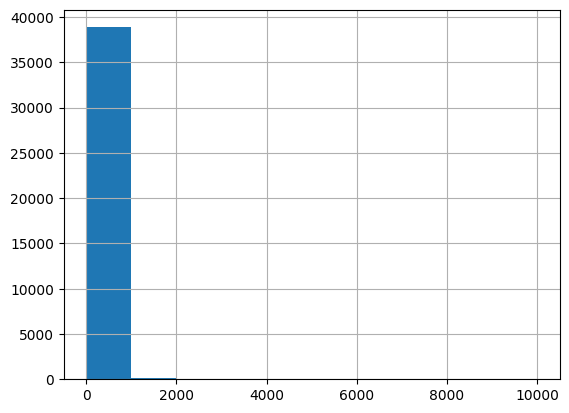

In [94]:
# 문제정의
# 평가: R-Squared, MAE, MSE, RMSE, MSLE, RMSLE, MAPE
# target: price(가격)
# 최종파일: result.csv(컬럼 1개 pred)

# 라이브러리 및 데이터 불러오기
import pandas as pd
train = pd.read_csv("https://raw.githubusercontent.com/lovedlim/inf/refs/heads/main/p2/ex2/train.csv")
test = pd.read_csv("https://raw.githubusercontent.com/lovedlim/inf/refs/heads/main/p2/ex2/test.csv")

# 탐색적 데이터 분석(EDA)
print("===== 데이터 크기 =====")
print("Train Shape:", train.shape)
print("Test Shape:", test.shape)

print("\n ===== 데이터 샘플 =====")
print(train.head(3))
print(test.head(2))

print("\n ===== 데이터 정보(자료형) =====")
print(train.info())

print("\n ===== train 결측치 수 =====")
print(train.isnull().sum())
print("\n ===== test 결측치 수 =====")
print(test.isnull().sum())

print("\n ===== 고유값 수 =====")
print(train.nunique())

print("\n ===== 타겟 분포 =====")
print(train['price'].describe())
train['price'].hist()


In [95]:
import pandas as pd
train = pd.read_csv("https://raw.githubusercontent.com/lovedlim/inf/refs/heads/main/p2/ex2/train.csv")
test = pd.read_csv("https://raw.githubusercontent.com/lovedlim/inf/refs/heads/main/p2/ex2/test.csv")

# 데이터 전처리
target = train.pop('price')

cols =['neighbourhood_group', 'neighbourhood', 'room_type']
from sklearn.preprocessing import LabelEncoder

for col in cols:
    le = LabelEncoder()
    train[col] = le.fit_transform(train[col])
    test[col] = le.transform(test[col])

print(train[cols].head())
print(train.shape, test.shape)

# 검증데이터 분리
from sklearn.model_selection import train_test_split
X_tr, X_val, y_tr, y_val = train_test_split(train, target, test_size=0.2, random_state=2022)
print(X_tr.shape, X_val.shape, y_tr.shape, y_val.shape)

# 평가
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, root_mean_squared_error
from sklearn.metrics import mean_squared_log_error, root_mean_squared_log_error, mean_absolute_percentage_error

# 랜덤포레스트
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor()
rf.fit(X_tr,y_tr)
pred = rf.predict(X_val)

print("랜덤포레스트")
print("r2: ",r2_score(y_val, pred))
print("mae: ",mean_absolute_error(y_val, pred))
print("mse: ",mean_squared_error(y_val, pred))
print("rmse: ",root_mean_squared_error(y_val, pred))
print("msle: ",mean_squared_log_error(y_val, pred.clip(0)))
print("rmsle: ",root_mean_squared_log_error(y_val, pred.clip(0)))
print("mape: ",mean_absolute_percentage_error(y_val, pred))


   neighbourhood_group  neighbourhood  room_type
0                    1             28          0
1                    2            206          0
2                    1             28          0
3                    1            214          0
4                    1             13          0
(39116, 10) (9779, 10)
(31292, 10) (7824, 10) (31292,) (7824,)
랜덤포레스트
r2:  0.14885768751084472
mae:  69.31752513633265
mse:  58573.214145190715
rmse:  242.01903674130827
msle:  0.2529123545542531
rmsle:  0.5029039217924762
mape:  52208139852058.75


In [96]:
# LightGBM
import lightgbm as lgb
lg = lgb.LGBMRegressor(random_state=2022, verbose=-1)
lg.fit(X_tr, y_tr)
pred = lg.predict(X_val)

print("lightgbm")
print("r2: ",r2_score(y_val, pred))
print("mae: ",mean_absolute_error(y_val, pred))
print("mse: ",mean_squared_error(y_val, pred))
print("rmse: ",root_mean_squared_error(y_val, pred))
print("msle: ",mean_squared_log_error(y_val, pred.clip(0)))
print("rmsle: ",root_mean_squared_log_error(y_val, pred.clip(0)))
print("mape: ",mean_absolute_percentage_error(y_val, pred))


lightgbm
r2:  0.15861681354714485
mae:  67.99107323055868
mse:  57901.61860728072
rmse:  240.62755163796334
msle:  0.2702579952956339
rmsle:  0.5198634390834134
mape:  39552482967627.77


In [97]:
# xgb
from xgboost import XGBRegressor

xg = XGBRegressor()
xg.fit(X_tr,y_tr)
pred=xg.predict(X_val)
print("xgboost")
print("r2: ",r2_score(y_val, pred))
print("mae: ",mean_absolute_error(y_val, pred))
print("mse: ",mean_squared_error(y_val, pred))
print("rmse: ",root_mean_squared_error(y_val, pred))
print("msle: ",mean_squared_log_error(y_val, pred.clip(0)))
print("rmsle: ",root_mean_squared_log_error(y_val, pred.clip(0)))
print("mape: ",mean_absolute_percentage_error(y_val, pred))


xgboost
r2:  0.14150959253311157
mae:  71.89957427978516
mse:  59078.88671875
rmse:  243.06149291992188
msle:  0.34992992877960205
rmsle:  0.5915487408638
mape:  47249883136000.0


In [98]:
# 최종제출
pred = rf.predict(test)
pred = pred.clip(0)

result = pd.DataFrame({'pred': pred})
result.to_csv("result.csv", index=False)

# 1. pred 행의 수와 test의 행의 수 비교
print("pred: ", pred.shape)  # test 행의 수: 9779

# 2. 생성한 csv 를 다시 읽어 확인
result = pd.read_csv("result.csv")
print(result.head())


pred:  (9779,)
     pred
0  322.41
1  163.43
2  164.06
3   73.51
4   54.14


In [99]:
# 모델별 음수 예측값 확인
pred = rf.predict(X_val)
print("랜덤포레스트 음수 예측값 개수:", (pred < 0).sum())

pred = lg.predict(X_val)
print("lightgbm 음수 예측값 개수:", (pred < 0).sum())

pred = xg.predict(X_val)
print("xgboost 음수 예측값 개수:", (pred < 0).sum())


랜덤포레스트 음수 예측값 개수: 0
lightgbm 음수 예측값 개수: 6
xgboost 음수 예측값 개수: 26
